In [1]:
%pip install pandas sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from pathlib import Path
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

In [3]:
DATA_DIR = Path("data") if Path("data").is_dir() else Path("../data")

In [ ]:
# 1. Connect to MySQL
engine = create_engine(
    URL.create(
        "mysql+pymysql",
        username="root",
        password=getpass("MySQL password: "),
        host="localhost",
        port=3306,
        database="sandwich_analytics"
    )
)

# 2. Select the latest 12 months
end_date = pd.Timestamp(
    pd.read_sql(
        "SELECT MAX(receipt_date) AS last_date FROM `01_receipts`",
        engine
    ).iloc[0, 0]
)

start_date = end_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)

print(f"Analysis period: {start_date.date()} to {end_date.date()}")

# 3. Load receipt items in chunks
query = text("""
    SELECT
        r.store_num,
        i.inv_num,
        i.quantity,
        i.sales_total,
        i.cost_total,
        i.cost_imputed
    FROM `03_items_receipt` i
    JOIN `01_receipts` r
        ON i.receipt_id = r.receipt_id
    WHERE r.receipt_date BETWEEN :start_date AND :end_date
""")

parts = []

with engine.connect().execution_options(stream_results=True) as conn:
    chunks = pd.read_sql(
        query,
        conn,
        params={
            "start_date": start_date.date(),
            "end_date": end_date.date()
        },
        chunksize=100_000
    )

    for chunk in chunks:
        chunk["estimated_cogs"] = (
            chunk["cost_total"] * chunk["cost_imputed"].fillna(0)
        )

        grouped = chunk.groupby(
            ["store_num", "inv_num"], as_index=False
        ).agg(
            units_sold=("quantity", "sum"),
            item_sales=("sales_total", "sum"),
            cogs=("cost_total", "sum"),
            estimated_cogs=("estimated_cogs", "sum")
        )

        parts.append(grouped)

# 4. Final aggregation in Pandas
df = pd.concat(parts, ignore_index=True)

df = df.groupby(["store_num", "inv_num"], as_index=False)[
    ["units_sold", "item_sales", "cogs", "estimated_cogs"]
].sum()

# 5. Add product and category information
menu = pd.read_sql("""
    SELECT
        inv_num,
        item_description,
        cat_description,
        sub_cat_description
    FROM `04_items_menu`
""", engine)

df = df.merge(menu, on="inv_num", how="left")

df["item_description"] = df["item_description"].fillna(
    "Unmapped #" + df["inv_num"].astype(str)
)
df["cat_description"] = df["cat_description"].fillna("Unmapped")

# 6. Financial KPIs
df["gross_profit"] = df["item_sales"] - df["cogs"]

df["gross_margin_pct"] = (
    df["gross_profit"] / df["item_sales"].where(df["item_sales"] != 0) * 100
)

df["avg_price"] = (
    df["item_sales"] / df["units_sold"].where(df["units_sold"] != 0)
)

df["unit_profit"] = (
    df["gross_profit"] / df["units_sold"].where(df["units_sold"] != 0)
)

# 7. Save dataset
DATA_DIR.mkdir(exist_ok=True)
df.to_csv(DATA_DIR / "menu_intelligence.csv", index=False)

# 8. Quick business overview
print("\nMENU INTELLIGENCE — BUSINESS OVERVIEW")
print("-----------------------------------")
print("Stores:", df["store_num"].nunique())
print("Products:", df["inv_num"].nunique())
print("Item Sales:", round(df["item_sales"].sum(), 2))
print("COGS:", round(df["cogs"].sum(), 2))
print("Gross Profit:", round(df["gross_profit"].sum(), 2))
print("Estimated COGS:", round(df["estimated_cogs"].sum(), 2))
print("Unmapped Products:", df.loc[
    df["cat_description"] == "Unmapped", "inv_num"
].nunique())

display(df.head())


Analysis period: 2012-05-17 to 2013-05-16

MENU INTELLIGENCE — BUSINESS OVERVIEW
-----------------------------------
Stores: 25
Products: 349
Item Sales: 12177668.92
COGS: 4120435.96
Gross Profit: 8057232.96
Estimated COGS: 6555.2
Unmapped Products: 188


,store_num,inv_num,units_sold,item_sales,cogs,estimated_cogs,item_description,cat_description,sub_cat_description,gross_profit,gross_margin_pct,avg_price,unit_profit
0,0,1,537,2554.75,590.8611,0.0,Unmapped #1,Unmapped,NaN,1963.8889,76.872058,4.757449,3.657149
1,0,2,16,98.50,23.2640,0.0,Unmapped #2,Unmapped,NaN,75.2360,76.381726,6.156250,4.702250
2,0,11,742,1990.00,750.9782,0.0,Unmapped #11,Unmapped,NaN,1239.0218,62.262402,2.681941,1.669841
3,0,12,38,172.75,48.5488,0.0,Unmapped #12,Unmapped,NaN,124.2012,71.896498,4.546053,3.268453
4,0,21,863,2479.00,1155.5570,0.0,Unmapped #21,Unmapped,NaN,1323.4430,53.386164,2.872538,1.533538


In [4]:
print("Full history:", pd.read_sql(
    "SELECT COUNT(DISTINCT inv_num) FROM `03_items_receipt`",
    engine
).iloc[0, 0])

print("Last 12 months:", df["inv_num"].nunique())

print("Unmapped sales:", round(
    df.loc[df["cat_description"] == "Unmapped", "item_sales"].sum()
    / df["item_sales"].sum() * 100, 2
), "%")

Full history: 672
Last 12 months: 349
Unmapped sales: 75.98 %


PARETO ANALYSIS
-----------------------------
Total Products: 349
Products generating 80% of sales: 33
Share of Products: 9.46 %


,inv_num,revenue,revenue_share_pct,cumulative_sales_pct
0,1651,867494.50,7.123650,7.123650
1,1611,682705.00,5.606204,12.729854
2,5014,570115.20,4.681645,17.411499
3,1501,506963.50,4.163059,21.574558
4,11519,448255.45,3.680963,25.255520
5,35050,437915.50,3.596054,28.851574
6,1631,424568.75,3.486453,32.338027
7,13821,419661.00,3.446152,35.784179
8,1511,392715.00,3.224878,39.009058
9,151,361508.25,2.968616,41.977674


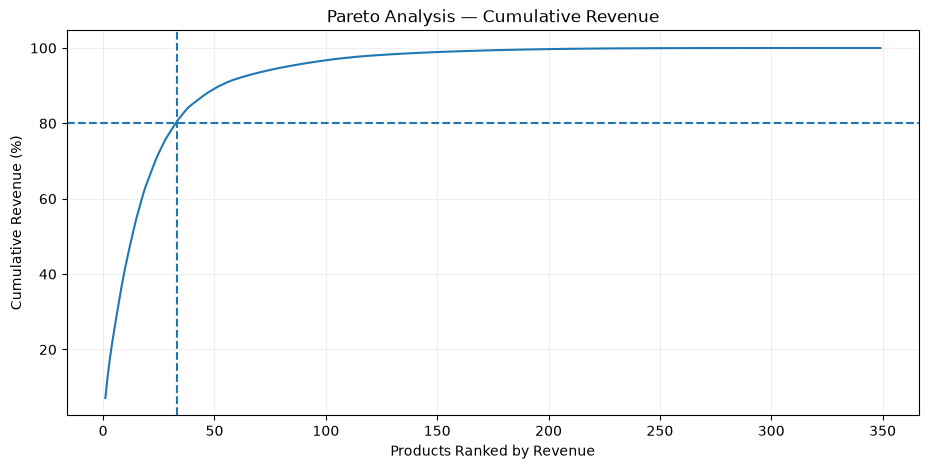


MENU ENGINEERING
-----------------------------
Median Units Sold: 437.0
Median Unit Profit: 4.24

Product Segments:
menu_segment
Plowhorse       103
Puzzle          103
Star             62
Dog              61
Unclassified     20
Name: count, dtype: int64


,menu_segment,products,revenue,gross_profit,units_sold,revenue_share_pct
0,Dog,61,34753.36,23476.34,8222,0.29
1,Plowhorse,103,8471690.47,5481200.38,2994289,69.57
2,Puzzle,103,74570.83,62102.84,9188,0.61
3,Star,62,3596698.00,2490506.48,525456,29.54
4,Unclassified,20,-43.74,-53.07,869,-0.00


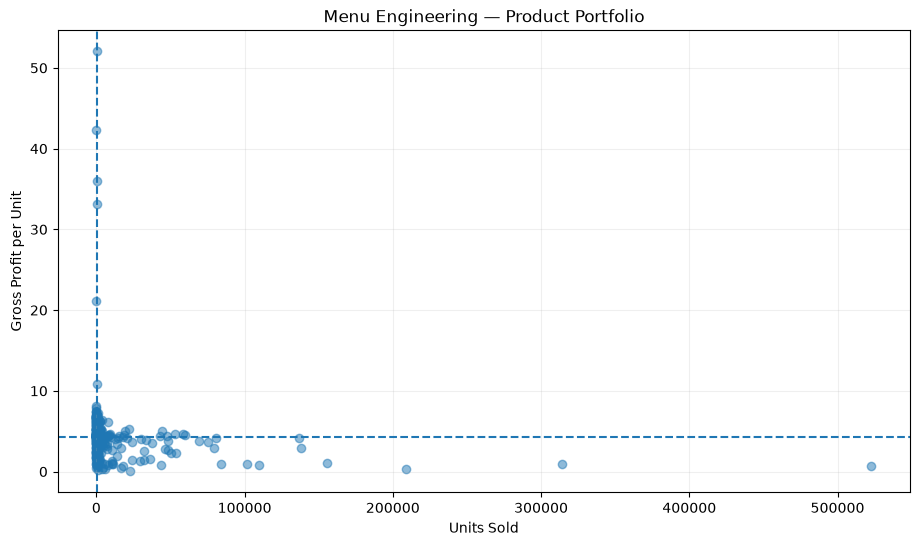


TOP 15 PRODUCTS BY GROSS PROFIT


,inv_num,units_sold,revenue,cogs,gross_profit,gross_margin_pct,menu_segment
0,1651,136951,867494.50,298315.17,569179.33,65.61,Plowhorse
1,1611,137819,682705.00,276765.52,405939.48,59.46,Plowhorse
2,5014,522824,570115.20,214127.97,355987.23,62.44,Plowhorse
3,1501,80393,506963.50,173369.06,333594.44,65.80,Plowhorse
4,11519,314370,448255.45,154929.07,293326.38,65.44,Plowhorse
9,151,75259,361508.25,83502.82,278005.43,76.90,Plowhorse
5,35050,58189,437915.50,165516.33,272399.17,62.20,Star
7,13821,60080,419661.00,147898.64,271762.36,64.76,Star
6,1631,69029,424568.75,159029.60,265539.15,62.54,Plowhorse
10,1561,53296,339296.25,91653.19,247643.06,72.99,Star



Analysis complete.
Saved: data/product_performance.csv
Saved previously: data/menu_intelligence.csv


In [ ]:

import matplotlib.pyplot as plt

# =====================================================
# 1. PRODUCT PERFORMANCE
# =====================================================

products = df.groupby("inv_num", as_index=False).agg(
    units_sold=("units_sold", "sum"),
    revenue=("item_sales", "sum"),
    cogs=("cogs", "sum"),
    estimated_cogs=("estimated_cogs", "sum")
)

products["gross_profit"] = products["revenue"] - products["cogs"]

products["gross_margin_pct"] = (
    products["gross_profit"]
    / products["revenue"].where(products["revenue"] != 0) * 100
)

products["unit_profit"] = (
    products["gross_profit"]
    / products["units_sold"].where(products["units_sold"] != 0)
)

products["avg_price"] = (
    products["revenue"]
    / products["units_sold"].where(products["units_sold"] != 0)
)

# =====================================================
# 2. PARETO ANALYSIS
# =====================================================

products = products.sort_values(
    "revenue", ascending=False
).reset_index(drop=True)

products["revenue_share_pct"] = (
    products["revenue"] / products["revenue"].sum() * 100
)

products["cumulative_sales_pct"] = (
    products["revenue_share_pct"].cumsum()
)

products["pareto_80"] = (
    products["cumulative_sales_pct"].shift(fill_value=0) < 80
)

top_80_count = products["pareto_80"].sum()

print("PARETO ANALYSIS")
print("-----------------------------")
print("Total Products:", len(products))
print("Products generating 80% of sales:", top_80_count)
print("Share of Products:", round(
    top_80_count / len(products) * 100, 2
), "%")

display(products[[
    "inv_num", "revenue", "revenue_share_pct",
    "cumulative_sales_pct"
]].head(15))

# Pareto chart
plt.figure(figsize=(11, 5))

plt.plot(
    range(1, len(products) + 1),
    products["cumulative_sales_pct"]
)

plt.axhline(80, linestyle="--")
plt.axvline(top_80_count, linestyle="--")

plt.title("Pareto Analysis — Cumulative Revenue")
plt.xlabel("Products Ranked by Revenue")
plt.ylabel("Cumulative Revenue (%)")
plt.grid(alpha=0.2)
plt.show()


# =====================================================
# 3. MENU ENGINEERING
# =====================================================

# Popularity = Units Sold
# Profitability = Gross Profit per Unit
# Thresholds = Chain Medians

valid = products[
    (products["units_sold"] > 0) &
    (products["revenue"] > 0)
].copy()

median_units = valid["units_sold"].median()
median_profit = valid["unit_profit"].median()

products["menu_segment"] = "Unclassified"

high_pop = products["units_sold"] >= median_units
high_profit = products["unit_profit"] >= median_profit
eligible = (
    (products["units_sold"] > 0) &
    (products["revenue"] > 0)
)

products.loc[
    eligible & high_pop & high_profit,
    "menu_segment"
] = "Star"

products.loc[
    eligible & high_pop & ~high_profit,
    "menu_segment"
] = "Plowhorse"

products.loc[
    eligible & ~high_pop & high_profit,
    "menu_segment"
] = "Puzzle"

products.loc[
    eligible & ~high_pop & ~high_profit,
    "menu_segment"
] = "Dog"

print("\nMENU ENGINEERING")
print("-----------------------------")
print("Median Units Sold:", round(median_units, 2))
print("Median Unit Profit:", round(median_profit, 2))
print("\nProduct Segments:")
print(products["menu_segment"].value_counts())

# Financial performance by segment
segment_summary = products.groupby(
    "menu_segment", as_index=False
).agg(
    products=("inv_num", "count"),
    revenue=("revenue", "sum"),
    gross_profit=("gross_profit", "sum"),
    units_sold=("units_sold", "sum")
)

segment_summary["revenue_share_pct"] = (
    segment_summary["revenue"]
    / products["revenue"].sum() * 100
)

display(segment_summary.round(2))

# Menu Engineering Matrix
plt.figure(figsize=(11, 6))

plt.scatter(
    valid["units_sold"],
    valid["unit_profit"],
    alpha=0.5
)

plt.axvline(median_units, linestyle="--")
plt.axhline(median_profit, linestyle="--")

plt.title("Menu Engineering — Product Portfolio")
plt.xlabel("Units Sold")
plt.ylabel("Gross Profit per Unit")
plt.grid(alpha=0.2)
plt.show()


# =====================================================
# 4. TOP PRODUCTS BY GROSS PROFIT
# =====================================================

print("\nTOP 15 PRODUCTS BY GROSS PROFIT")

display(
    products.sort_values(
        "gross_profit", ascending=False
    )[[
        "inv_num",
        "units_sold",
        "revenue",
        "cogs",
        "gross_profit",
        "gross_margin_pct",
        "menu_segment"
    ]].head(15).round(2)
)


# =====================================================
# 5. SAVE FOR STREAMLIT
# =====================================================

products.to_csv(
    DATA_DIR / "product_performance.csv", index=False
)

print("\nAnalysis complete.")
print("Saved: data/product_performance.csv")
print("Saved previously: data/menu_intelligence.csv")


In [4]:
print(DATA_DIR.resolve())

C:\Users\yurii\Downloads\fast_food_chain_analytics\data
